<a href="https://colab.research.google.com/github/NSmythe/Campus-Parking-Predictor/blob/main/COMP365_Campus_Parking_Predictor_Checkpoint3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 365 — Campus Parking Predictor
**Team:** Parallel Perfection  
**Members:** Aniya Teasley (Data and Evaluation Lead), Brianna Williams (Testing and Evaluation), Daiyana Brooks (Data Collection Lead), Natalia Smythe (ML Model Development)

## Practical Checkpoint 1 — working technical artifact
This notebook demonstrates the planned pipeline: parking observations → cleaning → baseline → initial machine-learning model → evaluation.

**Important:** The bundled sample is **synthetic demonstration data, not observed NC A&T parking availability**. The pitch did not include real observations. Results are demonstrations only and cannot establish real-world prediction accuracy. Replace the sample CSV with the team's actual observations before drawing campus conclusions.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
SEED = 365
print('Imports successful')

Imports successful


## 1. Input data
Expected columns: `parking_area`, `day_of_week`, `time_of_day`, `available` (1 = at least one open space observed; 0 = none). Record one row per parking-area observation. **Area names below are illustrative labels, not verified NC A&T parking lot names.**

In [ ]:
# Use a team-collected CSV if placed next to this notebook; otherwise make a reproducible synthetic demo.
input_file = Path('parking_observations.csv')
if input_file.exists():
    raw = pd.read_csv(input_file)
    data_source = 'TEAM CSV (user supplied; verify collection provenance)'
else:
    rng = np.random.default_rng(SEED)
    areas = ['Area A', 'Area B', 'Area C']
    days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
    hours = ['08:00', '10:00', '12:00', '14:00', '16:00']
    rows = []
    for repeat in range(5):
        for area in areas:
            for day in days:
                for hour in hours:
                    busy = (hour in ['10:00','12:00']) + (area == 'Area A') + (day in ['Tuesday','Thursday'])
                    p_open = {0:.87,1:.68,2:.35,3:.16}[int(busy)]
                    rows.append([area, day, hour, int(rng.random() < p_open)])
    raw = pd.DataFrame(rows, columns=['parking_area','day_of_week','time_of_day','available'])
    data_source = 'SYNTHETIC DEMONSTRATION ONLY'
    raw.to_csv('synthetic_parking_demo.csv', index=False)
print('Source:', data_source, '| rows:', len(raw))
display(raw.head())

Source: SYNTHETIC DEMONSTRATION ONLY | rows: 375


,parking_area,day_of_week,time_of_day,available
0,Area A,Monday,08:00,0
1,Area A,Monday,10:00,0
2,Area A,Monday,12:00,0
3,Area A,Monday,14:00,1
4,Area A,Monday,16:00,1


## 2. Validate and clean
Drop missing or duplicate records, normalize strings, validate the target, and show the class balance. Real observations should include a timestamp/observation ID so genuine repeated observations are not accidentally treated as duplicates; this checkpoint uses the four planned fields only.

In [ ]:
required = ['parking_area','day_of_week','time_of_day','available']
missing_cols = set(required) - set(raw.columns)
if missing_cols: raise ValueError(f'Missing required columns: {sorted(missing_cols)}')
df = raw[required].copy()
for col in required[:3]:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace('', pd.NA)
df['available'] = pd.to_numeric(df['available'], errors='coerce')
before = len(df)
df = df.dropna(subset=required)
df = df[df['available'].isin([0,1])].copy()
df['available'] = df['available'].astype(int)
# Repeated identical feature combinations may be legitimate observations at different dates.
# Do not drop them without a true observation identifier.
print('Rows removed for missing/invalid values:', before-len(df))
print('Exact repeated rows (retained until observation IDs are available):', df.duplicated().sum())
print('Clean rows:',len(df))
print('Class counts:',df['available'].value_counts().to_dict())

Rows removed for missing/invalid values: 0
Exact repeated rows (retained until observation IDs are available): 241
Clean rows: 375
Class counts: {1: 231, 0: 144}


## 3. Baseline and initial ML model
Use the same held-out split for both methods. The baseline always predicts the most frequent training label. The ML model is a shallow decision tree with one-hot encoding for categorical features. This is an initial checkpoint experiment, not a tuned final model. A real dataset collected across dates should eventually be tested with a chronological split to reduce leakage.

In [ ]:
features = ['parking_area','day_of_week','time_of_day']
X, y = df[features], df['available']
if len(df) < 20 or y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError('Need at least 20 valid rows and at least two examples of each class.')
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.25,random_state=SEED,stratify=y)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
model = Pipeline([('encode', ColumnTransformer([('categories',OneHotEncoder(handle_unknown='ignore'),features)])),('tree',DecisionTreeClassifier(max_depth=5,min_samples_leaf=5,random_state=SEED))])
model.fit(X_train,y_train)
pred_baseline = baseline.predict(X_test)
pred_model = model.predict(X_test)
results = pd.DataFrame([{'method':'Majority-class baseline','accuracy':accuracy_score(y_test,pred_baseline),'balanced_accuracy':balanced_accuracy_score(y_test,pred_baseline)}, {'method':'Decision tree ML','accuracy':accuracy_score(y_test,pred_model),'balanced_accuracy':balanced_accuracy_score(y_test,pred_model)}])
print('Train rows:',len(X_train),'Test rows:',len(X_test))
display(results.round(3))
print('ML classification report:')
print(classification_report(y_test,pred_model,zero_division=0))

Train rows: 281 Test rows: 94


,method,accuracy,balanced_accuracy
0,Majority-class baseline,0.617,0.500
1,Decision tree ML,0.723,0.665


ML classification report:
              precision    recall  f1-score   support

           0       0.75      0.42      0.54        36
           1       0.72      0.91      0.80        58

    accuracy                           0.72        94
   macro avg       0.73      0.67      0.67        94
weighted avg       0.73      0.72      0.70        94



## 4. Observable output and evaluation figure
Accuracy is the metric named in the pitch. Balanced accuracy is a second measure to check whether performance is misleading when one class is more common. Both are calculated on the same held-out demonstration set.

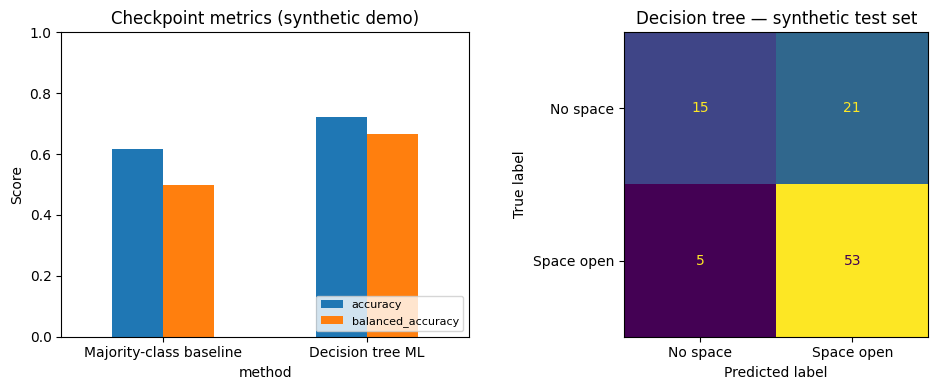

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
results.plot(x='method',y=['accuracy','balanced_accuracy'],kind='bar',ylim=(0,1),rot=0,ax=axes[0],title='Checkpoint metrics (synthetic demo)')
axes[0].set_ylabel('Score'); axes[0].legend(loc='lower right',fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test,pred_model,display_labels=['No space','Space open'],ax=axes[1],colorbar=False)
axes[1].set_title('Decision tree — synthetic test set')
fig.tight_layout()
fig.savefig('checkpoint_result.png',dpi=160,bbox_inches='tight')
plt.show()

## 5. Example prediction
A prediction is a **demonstration**, not a live campus parking recommendation.

In [ ]:
sample = pd.DataFrame([{'parking_area':'Area B','day_of_week':'Monday','time_of_day':'10:00'}])
print('Example input:',sample.to_dict('records')[0])
print('Predicted availability:', 'Likely open' if model.predict(sample)[0] == 1 else 'Likely full')
print('Demo data source:',data_source)

Example input: {'parking_area': 'Area B', 'day_of_week': 'Monday', 'time_of_day': '10:00'}
Predicted availability: Likely open
Demo data source: SYNTHETIC DEMONSTRATION ONLY


## 6. Interpretation, limitations, and next steps
- **What works:** accepts a correctly formatted CSV, cleans invalid rows, runs a majority-class baseline and a decision tree, reports accuracy/balanced accuracy, and plots results.
- **Not yet verified:** actual NC A&T observations, generalization to future days, a deployed user interface, and testing across devices.
- **Risks:** small or unrepresentative samples, event/weather effects, repeated observations, and changing lot rules. Do not collect license plates or identifying information.
- **Next checkpoint:** import actual team-collected observations with timestamps; document lot definitions and availability-label rules; evaluate on later observation dates; compare against baseline; integrate a basic interface.
- **Fallback:** reduce the number of parking areas and use the baseline if real observations are too limited for a reliable ML model.

**Responsibility:** Daiyana supplies observations; Aniya cleans data and develops baseline; Natalia builds the model; Brianna evaluates and tests integration.

## 7. Comparing Three Machine Learning Models


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Three ML models plus our original baseline
models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        random_state=SEED
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=SEED
    )
}

comparison = []
trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("encode", ColumnTransformer([
            ("categories",
             OneHotEncoder(handle_unknown="ignore"),
             features)
        ])),
        ("classifier", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))

best_name = comparison_df.loc[
    comparison_df["Balanced Accuracy"].idxmax(), "Model"
]
print("Highest balanced accuracy:", best_name)
print("Data source:", data_source)



,Model,Accuracy,Balanced Accuracy
0,Majority Baseline,0.617,0.500
1,Decision Tree,0.723,0.665
2,Logistic Regression,0.745,0.688
3,Random Forest,0.766,0.721


Highest balanced accuracy: Random Forest
Data source: SYNTHETIC DEMONSTRATION ONLY


## 8. Confusion Matrix and Evaluation Verification


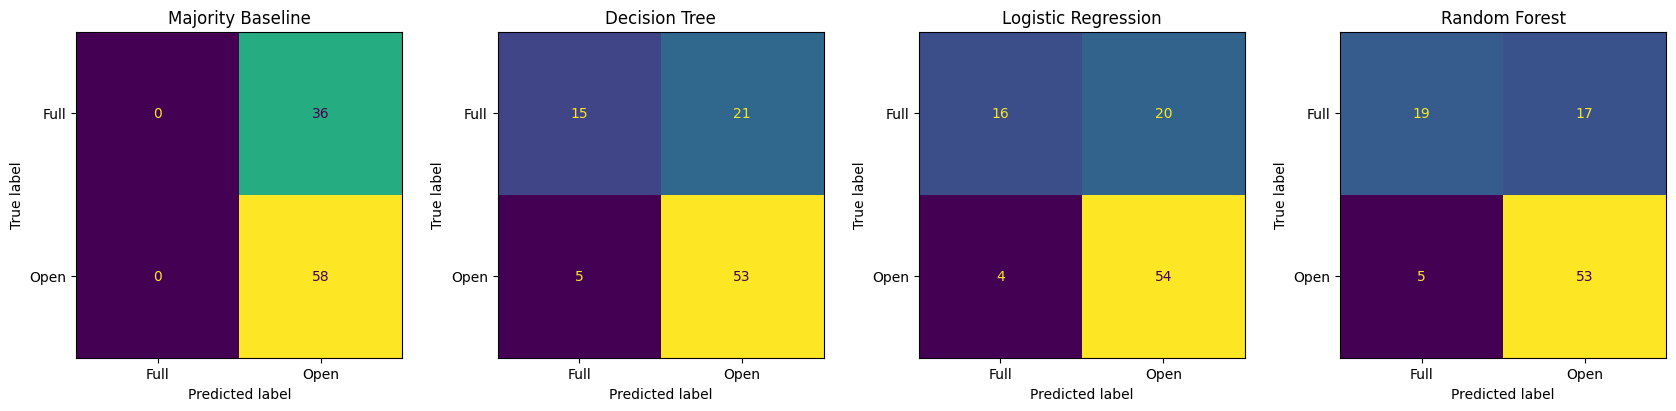

TN: 15 FP: 21 FN: 5 TP: 53
Verified accuracy: 0.723404255319149
Verified balanced accuracy: 0.6652298850574713


In [ ]:

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

for ax, (name, trained_model) in zip(
    axes, trained_models.items()
):
    predictions = trained_model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Full", "Open"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Verify Decision Tree metrics directly
tree_predictions = trained_models[
    "Decision Tree"
].predict(X_test)

cm = confusion_matrix(
    y_test, tree_predictions, labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
print("Verified accuracy:",
      accuracy_score(y_test, tree_predictions))
print("Verified balanced accuracy:",
      balanced_accuracy_score(y_test, tree_predictions))


## 9. Data Quality and Validation Testing

This section tests the reliability of our data-cleaning pipeline using intentionally invalid parking observations. We evaluate how the system handles missing values, incorrect availability labels, and inconsistent formatting. These tests help ensure that invalid records do not enter model training.


In [ ]:

# Section 9: Data Quality and Validation Testing
# Tests use intentionally invalid synthetic records.

test_data = pd.DataFrame({
    "parking_area": [
        "Area A", "Area B", None,
        " Area C ", "Area A", "Area B"
    ],
    "day_of_week": [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", None, "Friday"
    ],
    "time_of_day": [
        "08:00", "10:00", "12:00",
        "14:00", "16:00", "10:00"
    ],
    "available": [1, 0, 1, 1, 0, 5]
})

print("BEFORE CLEANING")
display(test_data)
print("Original records:", len(test_data))

# Apply the same validation rules as Section 2
test_clean = test_data.copy()

for col in ["parking_area", "day_of_week", "time_of_day"]:
    test_clean[col] = (
        test_clean[col].astype("string").str.strip()
    )
    test_clean[col] = test_clean[col].replace("", pd.NA)

test_clean["available"] = pd.to_numeric(
    test_clean["available"], errors="coerce"
)

test_clean = test_clean.dropna(
    subset=["parking_area", "day_of_week",
            "time_of_day", "available"]
)

test_clean = test_clean[
    test_clean["available"].isin([0, 1])
].copy()

test_clean["available"] = (
    test_clean["available"].astype(int)
)

print("\nAFTER CLEANING")
display(test_clean)

print("Original records:", len(test_data))
print("Valid records:", len(test_clean))
print("Invalid records removed:",
      len(test_data) - len(test_clean))

# Automated validation checks
assert len(test_clean) == 3
assert test_clean["available"].isin([0, 1]).all()
assert not test_clean.isna().any().any()
assert "Area C" in test_clean["parking_area"].values

print("\nALL DATA VALIDATION TESTS PASSED")


BEFORE CLEANING


,parking_area,day_of_week,time_of_day,available
0,Area A,Monday,08:00,1
1,Area B,Tuesday,10:00,0
2,None,Wednesday,12:00,1
3,Area C,Thursday,14:00,1
4,Area A,None,16:00,0
5,Area B,Friday,10:00,5


Original records: 6

AFTER CLEANING


,parking_area,day_of_week,time_of_day,available
0,Area A,Monday,08:00,1
1,Area B,Tuesday,10:00,0
3,Area C,Thursday,14:00,1


Original records: 6
Valid records: 3
Invalid records removed: 3

ALL DATA VALIDATION TESTS PASSED


## 10. Interactive Parking Prediction Demo

This section demonstrates how a trained machine learning model predicts parking availability from user-selected inputs. Predictions are based on synthetic demonstration data and do not represent verified real-time NC A&T parking availability.

In [ ]:

# Section 10: Interactive Parking Prediction Demo

import ipywidgets as widgets
from IPython.display import display, clear_output

area_input = widgets.Dropdown(
    options=["Area A", "Area B", "Area C"],
    description="Parking Area:"
)

day_input = widgets.Dropdown(
    options=["Monday", "Tuesday", "Wednesday",
             "Thursday", "Friday"],
    description="Day:"
)

time_input = widgets.Dropdown(
    options=["08:00", "10:00", "12:00",
             "14:00", "16:00"],
    description="Time:"
)

model_input = widgets.Dropdown(
    options=["Decision Tree", "Logistic Regression",
             "Random Forest"],
    description="ML Model:"
)

predict_button = widgets.Button(
    description="Predict Availability",
    button_style="success"
)

output = widgets.Output()

def make_prediction(button):
    with output:
        clear_output(wait=True)

        user_input = pd.DataFrame([{
            "parking_area": area_input.value,
            "day_of_week": day_input.value,
            "time_of_day": time_input.value
        }])

        selected_model = trained_models[model_input.value]
        prediction = selected_model.predict(user_input)[0]

        result = (
            "LIKELY OPEN" if prediction == 1
            else "LIKELY FULL"
        )

        print("Parking area:", area_input.value)
        print("Day:", day_input.value)
        print("Time:", time_input.value)
        print("Model:", model_input.value)
        print("Prediction:", result)
        print("Data source:", data_source)
        print("Demo only — not real-time parking availability.")

predict_button.on_click(make_prediction)

display(
    area_input,
    day_input,
    time_input,
    model_input,
    predict_button,
    output
)


Dropdown(description='Parking Area:', options=('Area A', 'Area B', 'Area C'), value='Area A')

Dropdown(description='Day:', options=('Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'), value='Monday')

Dropdown(description='Time:', options=('08:00', '10:00', '12:00', '14:00', '16:00'), value='08:00')

Dropdown(description='ML Model:', options=('Decision Tree', 'Logistic Regression', 'Random Forest'), value='De…

Button(button_style='success', description='Predict Availability', style=ButtonStyle())

Output()